# Selección de ETFs con un modelo de clasificación

Mi punto de partida fue revisar si un modelo podía ayudarme a seleccionar ETFs y cómo se comparaba esa selección con repartir el dinero entre todos por igual. Me interesa comparar el rendimiento, pero también las caídas y los costos de cambiar las posiciones.

Usé los métodos de Analytics in Stock Markets Zoomcamp: preparación de datos, variables derivadas, Decision Tree, Random Forest, separación temporal y simulación. Adapté el universo de activos y el horizonte de predicción. 

Este es un ejercicio histórico. Las señales al final corresponden al cierre de 2025, no a operaciones actuales.

## 1. Preparación

La primera celda instala las bibliotecas si hacen falta en Colab. En esta ejecución las bibliotecas ya estaban instaladas. Si trabajas desde una carpeta con los archivos del proyecto, puedes usar `pip install -r requirements.txt`.

In [ ]:
%pip -q install yfinance pandas numpy matplotlib scikit-learn

## 2. Funciones del proyecto

Esta celda escribe `etf_project.py`. El archivo reúne las funciones de descarga, preparación, entrenamiento, simulación y evaluación. Tenerlo separado permite ejecutar el mismo análisis desde un comando, como en el módulo de automatización.

Los imports se repiten dentro del archivo porque debe poder funcionar fuera del notebook. Todavía no se ejecuta el análisis en esta celda.

In [1]:
%%writefile etf_project.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score
from pathlib import Path

TICKERS = ["SPY", "QQQ", "IWM", "EFA", "EEM", "TLT", "IEF", "GLD"]


def download_prices(end="2026-01-01"):
    raw = yf.download(
        TICKERS,
        start="2010-01-01",
        end=end,
        auto_adjust=True,
        progress=False
    )

    if raw.empty:
        raise ValueError("No se descargaron datos.")

    prices = raw["Close"].reindex(columns=TICKERS).sort_index()

    if prices.isna().any().any():
        raise ValueError("Hay precios faltantes. Revisar la descarga.")

    if prices.index.duplicated().any():
        raise ValueError("Hay fechas duplicadas.")

    if not np.isfinite(prices.to_numpy()).all() or (prices <= 0).any().any():
        raise ValueError("Hay precios no válidos.")

    return prices


def prepare_data(prices):
    frames = []

    for ticker in TICKERS:
        p = prices[ticker]
        daily_return = p / p.shift(1) - 1

        df = pd.DataFrame(index=prices.index)
        df["Ticker"] = ticker

        # Información disponible al cierre de cada fecha.
        for window in [1, 5, 20, 60]:
            df[f"return_{window}"] = p / p.shift(window) - 1

        df["volatility_20"] = daily_return.rolling(20).std()
        df["relative_sma_10"] = p / p.rolling(10).mean() - 1
        df["relative_sma_20"] = p / p.rolling(20).mean() - 1
        df["relative_sma_60"] = p / p.rolling(60).mean() - 1

        df["Month"] = prices.index.month.astype(str)
        df["Weekday"] = prices.index.dayofweek.astype(str)

        # Señal al cierre de t.
        # Compra al cierre de t+1 y venta al cierre de t+2.
        df["future_return"] = p.shift(-2) / p.shift(-1) - 1

        # Fecha en que conocemos el resultado de la operación.
        df["label_end"] = pd.Series(
            prices.index, index=prices.index
        ).shift(-2)

        frames.append(df.rename_axis("Date").reset_index())

    data = pd.concat(frames, ignore_index=True)

    numeric = [
        "return_1", "return_5", "return_20", "return_60",
        "volatility_20",
        "relative_sma_10", "relative_sma_20", "relative_sma_60"
    ]

    dummies = pd.get_dummies(
        data[["Ticker", "Month", "Weekday"]],
        dtype=int
    )

    data = pd.concat([data, dummies], axis=1)
    features = numeric + dummies.columns.tolist()

    data = data.replace([np.inf, -np.inf], np.nan)
    data = data.dropna(subset=features).copy()

    # Las últimas filas quedan sin etiqueta: sirven para inferencia.
    data["target"] = np.where(
        data["future_return"].notna(),
        (data["future_return"] > 0).astype(int),
        np.nan
    )

    return data, features


def probability_up(model, X):
    class_position = list(model.classes_).index(1)
    return model.predict_proba(X)[:, class_position]


def train_models(data, features):
    labeled = data.dropna(subset=["target", "label_end"]).copy()

    # Separación cronológica y eliminación de etiquetas
    # que crucen al siguiente periodo.
    train = labeled[
        (labeled["Date"] < "2020-01-01")
        & (labeled["label_end"] < "2020-01-01")
    ]

    valid = labeled[
        (labeled["Date"] >= "2020-01-01")
        & (labeled["Date"] < "2023-01-01")
        & (labeled["label_end"] < "2023-01-01")
    ]

    test = labeled[labeled["Date"] >= "2023-01-01"]

    candidates = {
        "decision_tree": DecisionTreeClassifier(
            max_depth=4,
            min_samples_leaf=50,
            random_state=42
        ),
        "random_forest": RandomForestClassifier(
            n_estimators=100,
            max_depth=5,
            min_samples_leaf=50,
            random_state=42,
            n_jobs=-1
        )
    }

    validation_results = []

    for name, model in candidates.items():
        model.fit(train[features], train["target"].astype(int))
        prediction = model.predict(valid[features])

        validation_results.append({
            "model": name,
            "accuracy": accuracy_score(valid["target"], prediction),
            "precision": precision_score(
                valid["target"], prediction, zero_division=0
            )
        })

    validation_results = pd.DataFrame(validation_results)

    # Elegimos con validación, sin consultar el resultado de test.
    best_name = validation_results.sort_values(
        ["accuracy", "precision"], ascending=False
    ).iloc[0]["model"]

    best_model = candidates[best_name]

    development = labeled[
        (labeled["Date"] < "2023-01-01")
        & (labeled["label_end"] < "2023-01-01")
    ]

    best_model.fit(
        development[features],
        development["target"].astype(int)
    )

    test_prediction = best_model.predict(test[features])

    # Comparación sencilla: predecir siempre que subirá.
    always_up = np.ones(len(test), dtype=int)

    test_results = pd.DataFrame([
        {
            "model": best_name,
            "accuracy": accuracy_score(test["target"], test_prediction),
            "precision": precision_score(
                test["target"], test_prediction, zero_division=0
            )
        },
        {
            "model": "always_up",
            "accuracy": accuracy_score(test["target"], always_up),
            "precision": precision_score(
                test["target"], always_up, zero_division=0
            )
        }
    ])

    split_sizes = {
        "train": len(train),
        "validation": len(valid),
        "test": len(test)
    }

    return best_model, validation_results, test_results, split_sizes


def simulate(prices, target_weights, cost_rate=0.001):
    """
    Pesos al comienzo de cada intervalo cierre a cierre.
    El capital no invertido permanece en efectivo sin intereses.
    Costos aproximados sobre el volumen de compra y venta.
    """
    asset_returns = (
        prices / prices.shift(1) - 1
    ).reindex(target_weights.index)

    previous_weights = np.zeros(len(TICKERS))

    daily_results = []

    for date in target_weights.index:
        desired = target_weights.loc[date, TICKERS].to_numpy(float)
        returns_today = asset_returns.loc[date, TICKERS].to_numpy(float)

        turnover = np.abs(desired - previous_weights).sum()
        cost = cost_rate * turnover

        gross_return = np.dot(desired, returns_today)

        # Primero descontamos costos y después aplicamos el rendimiento.
        net_return = (1 - cost) * (1 + gross_return) - 1

        daily_results.append({
            "Date": date,
            "net_return": net_return,
            "turnover": turnover,
            "cost_fraction": cost
        })

        # Pesos después del movimiento del mercado.
        previous_weights = (
            desired * (1 + returns_today) / (1 + gross_return)
        )

    result = pd.DataFrame(daily_results).set_index("Date")
    result["equity"] = (1 + result["net_return"]).cumprod()

    # Incluye el capital inicial de 1 en el máximo histórico.
    high_water = result["equity"].cummax().clip(lower=1)
    result["drawdown"] = result["equity"] / high_water - 1

    return result


def summarize(result):
    r = result["net_return"]
    equity_final = result["equity"].iloc[-1]
    annual_volatility = r.std() * np.sqrt(252)

    sharpe = (
        r.mean() / r.std() * np.sqrt(252)
        if r.std() > 0 else np.nan
    )

    return {
        "total_return": equity_final - 1,
        "CAGR": equity_final ** (252 / len(r)) - 1,
        "annual_volatility": annual_volatility,
        "max_drawdown": result["drawdown"].min(),
        "sharpe_rf_0": sharpe,
        "total_turnover": result["turnover"].sum()
    }


def run_project(prices, output_dir="results"):
    prices = prices.reindex(columns=TICKERS).sort_index()

    if prices.isna().any().any() or prices.index.duplicated().any():
        raise ValueError("Revisar faltantes o fechas duplicadas.")

    data, features = prepare_data(prices)

    model, validation, test, sizes = train_models(data, features)

    signals = data[data["Date"] >= "2023-01-01"].copy()
    signals["probability_up"] = probability_up(
        model, signals[features]
    )

    probabilities = signals.pivot(
        index="Date", columns="Ticker", values="probability_up"
    ).reindex(index=prices.index, columns=TICKERS)

    # Umbral fijo del proyecto, no optimizado con test.
    # Cada ETF puede ocupar 1/8 del capital.
    signal_weights = probabilities.ge(0.55).astype(float) / len(TICKERS)

    # Señal de t ejecutada al cierre de t+1:
    # obtiene el rendimiento que termina en t+2.
    executed_weights = signal_weights.shift(2).fillna(0)

    first_signal_date = signals["Date"].min()
    first_position = prices.index.get_loc(first_signal_date) + 2
    evaluation_dates = prices.index[first_position:]

    strategy_weights = executed_weights.loc[evaluation_dates]

    equal_weights = pd.DataFrame(
        1 / len(TICKERS),
        index=evaluation_dates,
        columns=TICKERS
    )

    strategy = simulate(prices, strategy_weights)
    benchmark = simulate(prices, equal_weights)

    metrics = pd.DataFrame({
        "model_strategy": summarize(strategy),
        "equal_weight_daily": summarize(benchmark)
    }).T

    importance = pd.Series(
        model.feature_importances_, index=features
    ).sort_values(ascending=False)

    # El modelo se entrenó con datos anteriores a 2023.
    # Estas son probabilidades de investigación, no órdenes reales.
    latest = signals[
        signals["Date"] == signals["Date"].max()
    ][["Date", "Ticker", "probability_up"]].copy()

    latest["signal"] = (latest["probability_up"] >= 0.55).astype(int)

    folder = Path(output_dir)
    folder.mkdir(parents=True, exist_ok=True)

    validation.to_csv(folder / "validation_metrics.csv", index=False)
    test.to_csv(folder / "test_metrics.csv", index=False)
    metrics.to_csv(folder / "portfolio_metrics.csv")
    latest.to_csv(folder / "latest_signals.csv", index=False)
    importance.to_csv(folder / "feature_importance.csv")
    strategy.to_csv(folder / "strategy_history.csv")
    benchmark.to_csv(folder / "benchmark_history.csv")

    fig, ax = plt.subplots(figsize=(12, 5))
    strategy["equity"].plot(ax=ax, label="Estrategia del modelo")
    benchmark["equity"].plot(ax=ax, label="Pesos iguales diarios")
    ax.set_title("Evaluación fuera de muestra")
    ax.set_ylabel("Capital relativo")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(folder / "equity_comparison.png", dpi=150)
    plt.show()

    extra_checks(prices, data, features, signals, folder)

    return {
        "validation": validation,
        "test": test,
        "metrics": metrics,
        "importance": importance,
        "latest": latest,
        "split_sizes": sizes
    }



def extra_checks(prices, data, features, signals, folder):
    # Reviso la disponibilidad antes de interpretar las gráficas.
    availability = pd.DataFrame({
        "observaciones": prices.count(),
        "faltantes": prices.isna().sum(),
        "primera_fecha": prices.apply(lambda x: x.first_valid_index()),
        "ultima_fecha": prices.apply(lambda x: x.last_valid_index())
    })
    availability.to_csv(folder / "data_availability.csv")
    returns = (prices / prices.shift(1) - 1).iloc[1:]
    returns.corr().to_csv(folder / "return_correlations.csv")
    returns.describe().to_csv(folder / "return_summary.csv")

    # Para la exploración del objetivo uso solamente el desarrollo.
    development = data[
        (data["Date"] < "2023-01-01")
        & (data["label_end"] < "2023-01-01")
    ]
    development.groupby("Ticker")["target"].agg(["count", "mean"]).to_csv(
        folder / "target_by_ticker_development.csv"
    )
    development[features + ["target"]].corr()["target"].drop("target").sort_values().to_csv(
        folder / "feature_target_correlations_development.csv"
    )

    # Simulación vectorizada, como primer ejercicio del módulo 4.
    # Cada fila supone una operación independiente de 100 USD.
    trades = signals.dropna(subset=["future_return"]).copy()
    trades["selected"] = (trades["probability_up"] >= 0.55).astype(int)
    trades["gross_profit_usd"] = trades["selected"] * 100 * trades["future_return"]
    trades["fees_usd"] = trades["selected"] * 100 * 0.002
    trades["net_profit_usd"] = trades["gross_profit_usd"] - trades["fees_usd"]
    trades[["Date", "Ticker", "future_return", "selected", "gross_profit_usd", "fees_usd", "net_profit_usd"]].to_csv(
        folder / "independent_trade_simulation.csv", index=False
    )
    # Este total no es un rendimiento de portafolio: no fija el capital disponible.
    pd.DataFrame([{
        "selected_trades": int(trades["selected"].sum()),
        "gross_profit_usd": trades["gross_profit_usd"].sum(),
        "fees_usd": trades["fees_usd"].sum(),
        "net_profit_usd": trades["net_profit_usd"].sum()
    }]).to_csv(folder / "independent_trade_summary.csv", index=False)

    fig, ax = plt.subplots(figsize=(11, 5))
    (prices / prices.iloc[0] * 100).plot(ax=ax)
    ax.set(title="Evolución histórica: inicio = 100", ylabel="Valor relativo")
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(folder / "normalized_prices.png", dpi=150)
    plt.close(fig)

    corr = returns.corr()
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(corr)), corr.columns, rotation=45)
    ax.set_yticks(range(len(corr)), corr.index)
    for i in range(len(corr)):
        for j in range(len(corr)):
            ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title("Correlación de rendimientos diarios: descriptivo 2010–2025")
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    fig.savefig(folder / "correlations.png", dpi=150)
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(11, 4))
    for filename, label in [("strategy_history.csv", "Modelo"), ("benchmark_history.csv", "Pesos iguales")]:
        history = pd.read_csv(folder / filename, index_col=0, parse_dates=True)
        (history["drawdown"] * 100).plot(ax=ax, label=label)
    ax.set(title="Caídas desde máximos: periodo de prueba", ylabel="Caída (%)")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(folder / "drawdown_comparison.png", dpi=150)
    plt.close(fig)


if __name__ == "__main__":
    prices = download_prices()
    results = run_project(prices)

    print("Tamaños de los conjuntos:", results["split_sizes"])
    print("\nValidación:\n", results["validation"])
    print("\nTest:\n", results["test"])
    print("\nPortafolios:\n", results["metrics"])
    print("\nSeñales más recientes:\n", results["latest"])


Overwriting etf_project.py


## 3. Descarga y revisión de los datos

Descargo precios ajustados de Yahoo Finance para ocho ETFs: SPY, QQQ, IWM, EFA, EEM, TLT, IEF y GLD. El periodo va de 2010 a 2025. La fecha final de la API es exclusiva.

La función detiene el flujo si encuentra faltantes, duplicados o precios no válidos. Esto no prueba que el proveedor no tenga errores; es una primera revisión. Cada fila es una sesión, no un día calendario.

In [2]:
import importlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import etf_project

importlib.reload(etf_project)
prices = etf_project.download_prices()
summary = pd.DataFrame({
    "observaciones": prices.count(),
    "faltantes": prices.isna().sum(),
    "primera_fecha": prices.apply(lambda x: x.first_valid_index()),
    "ultima_fecha": prices.apply(lambda x: x.last_valid_index())
})
print("Dimensiones:", prices.shape)
print("Fechas duplicadas:", prices.index.duplicated().sum())
display(summary)
display(prices.head())

Dimensiones: (4024, 8)
Fechas duplicadas: 0


,observaciones,faltantes,primera_fecha,ultima_fecha
Ticker,,,,
SPY,4024,0,2010-01-04,2025-12-31
QQQ,4024,0,2010-01-04,2025-12-31
IWM,4024,0,2010-01-04,2025-12-31
EFA,4024,0,2010-01-04,2025-12-31
EEM,4024,0,2010-01-04,2025-12-31
TLT,4024,0,2010-01-04,2025-12-31
IEF,4024,0,2010-01-04,2025-12-31
GLD,4024,0,2010-01-04,2025-12-31


Ticker,SPY,QQQ,IWM,EFA,EEM,TLT,IEF,GLD
Date,,,,,,,,
2010-01-04,84.368973,40.204659,51.111225,34.581207,30.194561,54.620010,60.299927,109.800003
2010-01-05,84.592316,40.204659,50.935471,34.611683,30.413727,54.972752,60.564690,109.699997
2010-01-06,84.651878,39.962154,50.887539,34.757988,30.477343,54.236858,60.320274,111.510002
2010-01-07,85.009216,39.988148,51.263004,34.623878,30.300606,54.328072,60.320274,110.820000
2010-01-08,85.292099,40.317253,51.542603,34.898193,30.540972,54.303776,60.394962,111.370003


## 4. Rendimientos y primera comparación

Calculo el rendimiento como precio actual dividido entre el anterior, menos uno. Una cifra de 0.01 equivale al 1 %. Después llevo los precios a una base de 100 para comparar su evolución.

Estas gráficas de todo el periodo son descriptivas. No se usan para ajustar los modelos ni cambiar las reglas después de ver el periodo de prueba.

In [3]:
returns = (prices / prices.shift(1) - 1).iloc[1:]
print("Rendimientos diarios en porcentaje:")
display((returns.head() * 100).round(2))
ax = (prices / prices.iloc[0] * 100).plot(figsize=(11, 5))
ax.set(title="Precios ajustados: inicio = 100", ylabel="Valor relativo")
ax.grid(alpha=0.25)
plt.show()
display(returns.corr().round(2))

Rendimientos diarios en porcentaje:


Ticker,SPY,QQQ,IWM,EFA,EEM,TLT,IEF,GLD
Date,,,,,,,,
2010-01-05,0.26,0.00,-0.34,0.09,0.73,0.65,0.44,-0.09
2010-01-06,0.07,-0.60,-0.09,0.42,0.21,-1.34,-0.40,1.65
2010-01-07,0.42,0.07,0.74,-0.39,-0.58,0.17,0.00,-0.62
2010-01-08,0.33,0.82,0.55,0.79,0.79,-0.04,0.12,0.50
2010-01-11,0.14,-0.41,-0.40,0.82,-0.21,-0.55,0.07,1.33


Ticker,SPY,QQQ,IWM,EFA,EEM,TLT,IEF,GLD
Ticker,,,,,,,,
SPY,1.00,0.93,0.88,0.86,0.78,-0.30,-0.26,0.05
QQQ,0.93,1.00,0.80,0.76,0.73,-0.23,-0.21,0.05
IWM,0.88,0.80,1.00,0.80,0.73,-0.27,-0.24,0.06
EFA,0.86,0.76,0.80,1.00,0.85,-0.29,-0.24,0.14
EEM,0.78,0.73,0.73,0.85,1.00,-0.25,-0.22,0.18
TLT,-0.30,-0.23,-0.27,-0.29,-0.25,1.00,0.92,0.22
IEF,-0.26,-0.21,-0.24,-0.24,-0.22,0.92,1.00,0.28
GLD,0.05,0.05,0.06,0.14,0.18,0.22,0.28,1.00


## 5. Variables y objetivo

Uso rendimientos pasados de 1, 5, 20 y 60 sesiones, volatilidad de 20 sesiones y distancia respecto a medias de 10, 20 y 60 sesiones. También incluyo variables indicadoras de ETF, mes y día de la semana.

El objetivo vale 1 si el rendimiento futuro es positivo y 0 en caso contrario. La señal se calcula al cierre de t, se supone una ejecución al cierre de t+1 y se evalúa el cambio hasta el cierre de t+2. Así no se utiliza el cierre observado de t como si se hubiera podido negociar después de conocerlo.

Las primeras observaciones se pierden porque las ventanas requieren historia. Las últimas dos no tienen resultado futuro conocido y quedan para inferencia, no para entrenamiento.

In [4]:
data, features = etf_project.prepare_data(prices)
print("Número de variables predictoras:", len(features))
print("Variables:", features)
display(data[["Date", "Ticker", "return_20", "volatility_20", "future_return", "target"]].head())
development = data[(data.Date < "2023-01-01") & (data.label_end < "2023-01-01")]
display(development.groupby("Ticker")["target"].agg(["count", "mean"]))
display(development[features + ["target"]].corr()["target"].drop("target").sort_values())

Número de variables predictoras: 33
Variables: ['return_1', 'return_5', 'return_20', 'return_60', 'volatility_20', 'relative_sma_10', 'relative_sma_20', 'relative_sma_60', 'Ticker_EEM', 'Ticker_EFA', 'Ticker_GLD', 'Ticker_IEF', 'Ticker_IWM', 'Ticker_QQQ', 'Ticker_SPY', 'Ticker_TLT', 'Month_1', 'Month_10', 'Month_11', 'Month_12', 'Month_2', 'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8', 'Month_9', 'Weekday_0', 'Weekday_1', 'Weekday_2', 'Weekday_3', 'Weekday_4']


,Date,Ticker,return_20,volatility_20,future_return,target
60,2010-03-31,SPY,0.046142,0.004769,0.008150,1.0
61,2010-04-01,SPY,0.050116,0.004876,0.002358,1.0
62,2010-04-05,SPY,0.043755,0.004244,-0.005712,0.0
63,2010-04-06,SPY,0.046033,0.004218,0.003464,1.0
64,2010-04-07,SPY,0.038332,0.004580,0.006567,1.0


,count,mean
Ticker,,
EEM,3210,0.517757
EFA,3210,0.529595
GLD,3210,0.522741
IEF,3210,0.519938
IWM,3210,0.535202
QQQ,3210,0.553894
SPY,3210,0.547664
TLT,3210,0.524922


Weekday_3         -0.020240
Month_9           -0.017255
Weekday_1         -0.011762
return_5          -0.011429
Ticker_EEM        -0.010382
relative_sma_20   -0.009806
relative_sma_10   -0.009336
Month_10          -0.009202
Ticker_IEF        -0.008731
Month_11          -0.007406
Ticker_GLD        -0.006607
Month_5           -0.005577
Ticker_TLT        -0.004955
return_20         -0.003060
Ticker_EFA        -0.001416
Month_6           -0.000271
Month_8            0.000069
relative_sma_60    0.000908
volatility_20      0.001362
Month_3            0.002144
Ticker_IWM         0.002832
Month_4            0.002898
Month_1            0.006146
return_60          0.006404
return_1           0.007234
Month_12           0.007715
Weekday_0          0.008146
Weekday_4          0.009193
Month_7            0.010342
Month_2            0.011530
Ticker_SPY         0.012270
Weekday_2          0.014900
Ticker_QQQ         0.016989
Name: target, dtype: float64

## 6. Entrenamiento y simulación

Comparo un árbol y un bosque aleatorio. Entreno con datos anteriores a 2020, elijo el modelo por accuracy en 2020–2022 y lo evalúo desde 2023. Quito las etiquetas que cruzan los límites temporales. Después de seleccionar, reentreno con los datos de desarrollo disponibles antes de 2023.

La simulación usa un umbral fijo de 0.55. Cada ETF ocupa como máximo 1/8 del capital; si no tiene señal, esa parte queda en efectivo sin intereses. La referencia mantiene pesos iguales con rebalanceo diario. Ambas consideran un costo aproximado del 0.1 % por lado sobre el volumen operado.

La accuracy se mide con la clase predicha por el modelo; la simulación aplica el umbral de 0.55. Son evaluaciones diferentes. No optimicé ese umbral usando test.

In [5]:
results = etf_project.run_project(prices)
print("Filas por conjunto:", results["split_sizes"])
print("Validación:")
display(results["validation"])
print("Test:")
display(results["test"])
print("Portafolios:")
display(results["metrics"].round(4))
print("Variables con mayor importancia en el árbol:")
display(results["importance"].head(15))

Filas por conjunto: {'train': 19632, 'validation': 6032, 'test': 6000}
Validación:
Test:
Portafolios:
Variables con mayor importancia en el árbol:


,model,accuracy,precision
0,decision_tree,0.512268,0.514626
1,random_forest,0.509781,0.513518


,model,accuracy,precision
0,decision_tree,0.5425,0.544414
1,always_up,0.5390,0.539000


,total_return,CAGR,annual_volatility,max_drawdown,sharpe_rf_0,total_turnover
model_strategy,0.0209,0.0070,0.0156,-0.0238,0.4532,31.8313
equal_weight_daily,0.5895,0.1685,0.1098,-0.1093,1.4732,5.0105


relative_sma_20    0.237009
return_1           0.229118
return_20          0.153682
return_60          0.139213
volatility_20      0.131914
return_5           0.071143
relative_sma_10    0.037922
relative_sma_60    0.000000
Ticker_EEM         0.000000
Ticker_EFA         0.000000
Ticker_GLD         0.000000
Ticker_IEF         0.000000
Ticker_IWM         0.000000
Ticker_QQQ         0.000000
Ticker_SPY         0.000000
dtype: float64

## 7. Caídas y operaciones independientes

El drawdown muestra cuánto cae el capital respecto a su máximo anterior. También incluyo la simulación vectorizada del módulo 4, con operaciones independientes de 100 USD y un costo de ida y vuelta de 0.2 %.

La suma de esas operaciones independientes no representa el rendimiento de un portafolio con capital limitado. Para esa comparación uso la simulación secuencial, que mantiene el capital disponible y permite reinvertirlo. No se agrega una liquidación final de todas las posiciones; el capital final se valora a mercado.

Señales históricas más recientes; modelo entrenado antes de 2023:


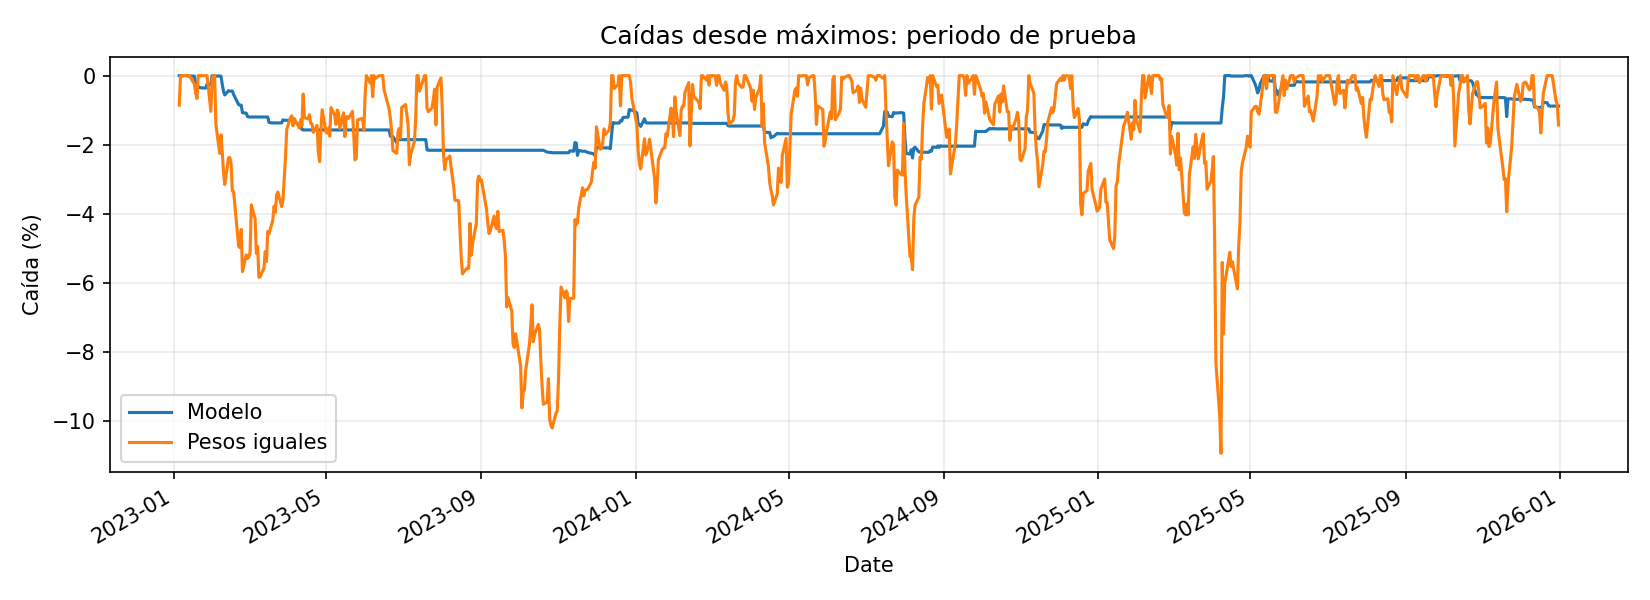

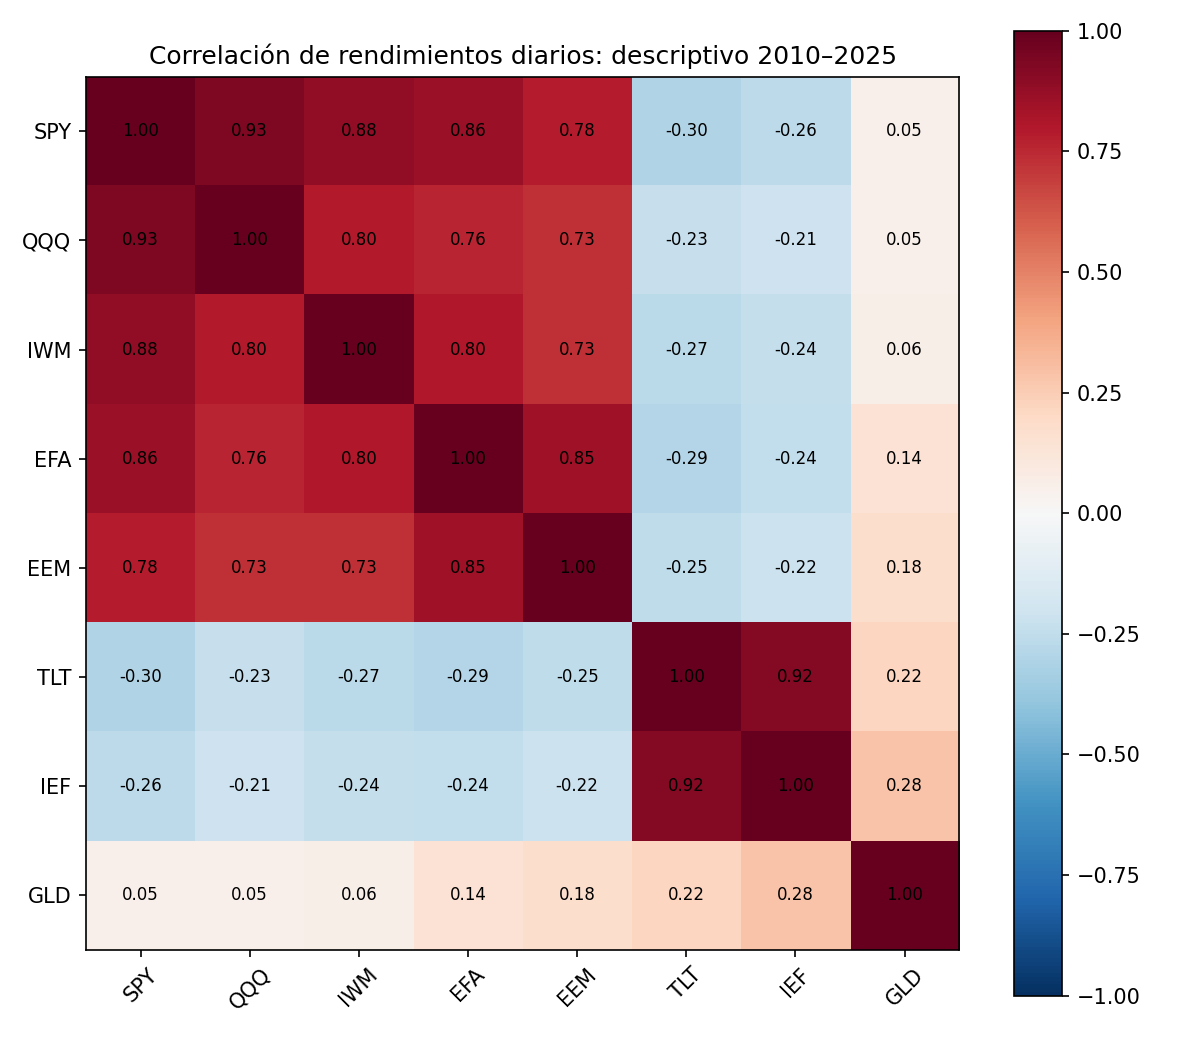

,selected_trades,gross_profit_usd,fees_usd,net_profit_usd
0,183,42.335113,36.6,5.735113


,Date,Ticker,probability_up,signal
4023,2025-12-31,SPY,0.540611,0
8047,2025-12-31,QQQ,0.540611,0
12071,2025-12-31,IWM,0.540611,0
16095,2025-12-31,EFA,0.540611,0
20119,2025-12-31,EEM,0.540611,0
24143,2025-12-31,TLT,0.540611,0
28167,2025-12-31,IEF,0.540611,0
32191,2025-12-31,GLD,0.632959,1


In [6]:
from IPython.display import Image, display
display(Image(filename="results/drawdown_comparison.png"))
display(Image(filename="results/correlations.png"))
display(pd.read_csv("results/independent_trade_summary.csv"))
print("Señales históricas más recientes; modelo entrenado antes de 2023:")
display(results["latest"])

## 8. Cómo volver a ejecutarlo

En una terminal: `python etf_project.py`. El script descarga los datos y genera los resultados. En este notebook se ejecutó el mismo flujo llamando `run_project`.

Los CSV y las imágenes de `results/` son salidas del análisis, no la base original de precios. Los datos se obtienen desde la API y no se suben como archivos de precios al repositorio.

Yahoo puede revisar datos ajustados y las versiones numéricas también pueden afectar resultados. Por eso una nueva descarga puede producir diferencias pequeñas. Se guardan las versiones del entorno y la fecha del corte histórico.

## Lo que encontré

El árbol fue el modelo elegido en validación. En test tuvo una accuracy de 54.25%, frente a 53.90% al predecir siempre una subida. La diferencia fue de 0.35 puntos porcentuales. Es una diferencia pequeña. No hice una prueba estadística para saber si se sostiene más allá de esta muestra. Además, las observaciones de varios ETFs en una misma fecha no son independientes.

| Indicador | Modelo | Pesos iguales diarios |
|---|---:|---:|
| Rendimiento acumulado | 2.09% | 58.95% |
| Rendimiento anual compuesto | 0.70% | 16.85% |
| Volatilidad anualizada | 1.56% | 10.98% |
| Caída máxima | -2.38% | -10.93% |
| Sharpe (tasa 0 %) | 0.453 | 1.473 |

En esta simulación, seleccionar ETFs con el modelo no mejoró el rendimiento frente a repartir el capital por igual. La estrategia ganó 2.09%, mientras que la referencia ganó 58.95%. El Sharpe también fue menor.

La estrategia presentó una caída máxima menor, pero también invirtió menos capital porque dejaba posiciones en efectivo cuando no había señal. Por eso no puedo atribuir esa diferencia solamente a una mejor selección de activos. Para separar esos efectos habría que comparar portafolios con una proporción invertida similar.

Lo que más me llamó la atención es que acertar un poco más no se tradujo en ganar más. También importan cuánto se gana o pierde en cada operación, los costos y cuánto capital permanece invertido.

Dejé los parámetros como estaban antes de revisar test. Si continúo con otras variables o con una frecuencia distinta de rebalanceo, necesitaré otro periodo de evaluación para no elegir las reglas que mejor se acomoden a estos resultados.
